In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/priyankasingh27/grandstaff/train-00000-of-00001.parquet
/kaggle/input/datasets/priyankasingh27/grandstaff/test-00000-of-00001.parquet
/kaggle/input/datasets/priyankasingh27/grandstaff/val-00000-of-00001.parquet


In [2]:
import io, json, math, os, random, collections, time
import numpy as np, pandas as pd, torch
from PIL import Image

CFG = dict(
    arch="transformer",          # "transformer" | "rnn"
    epochs=20, batch_size=16, lr=3e-4, warmup_steps=500,
    dropout=0.1, d_model=256, layers=4, heads=8,
    max_train_w=1600, max_train_tok=1000,
    val_subset=1000, seed=0,
    out_dir="/kaggle/working",
)
H = 256
dev = "cuda"

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])

root = "/kaggle/input/datasets/priyankasingh27/grandstaff"
dfs = {s: pd.read_parquet(f"{root}/{s}-00000-of-00001.parquet") for s in ["train", "val", "test"]}
print({s: len(d) for s, d in dfs.items()})        # 41598 / 4623 / 7661

# ---- lossless tokenizer ----
SEP = {"<s>": " ", "<t>": "\t", "<b>": "\n"}

def tokenize(s):
    s = s.replace(" ", " <s> ").replace("\t", " <t> ").replace("\n", " <b> ").replace("·", " ")
    return s.split()

def detokenize(toks):
    out, prev_sep = [], True
    for t in toks:
        if t in SEP:
            out.append(SEP[t]); prev_sep = True
        else:
            if not prev_sep: out.append("·")
            out.append(t); prev_sep = False
    return "".join(out)

for split, d in dfs.items():
    print(split, "round-trip failures:", sum(detokenize(tokenize(s)) != s for s in d["transcription"]))

{'train': 41598, 'val': 4623, 'test': 7661}
train round-trip failures: 0
val round-trip failures: 0
test round-trip failures: 0


In [3]:
from torch.utils.data import Dataset, DataLoader, Subset, Sampler
from torch.nn.utils.rnn import pad_sequence

# ---- vocab from train only, saved for inference ----
counter = collections.Counter(t for s in dfs["train"]["transcription"] for t in tokenize(s))
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
itos = SPECIALS + sorted(counter)
stoi = {t: i for i, t in enumerate(itos)}
PAD, BOS, EOS, UNK = 0, 1, 2, 3
json.dump(itos, open(f"{CFG['out_dir']}/vocab.json", "w"))

def encode(s):
    return [BOS] + [stoi.get(t, UNK) for t in tokenize(s)] + [EOS]

def decode(ids):
    toks = []
    for i in ids:
        if i == EOS: break
        if i not in (PAD, BOS): toks.append(itos[i])
    return detokenize(toks)

class GrandStaff(Dataset):
    def __init__(self, df, augment=None):          # augment hook stays None until Step 7
        self.img_bytes = [d["bytes"] for d in df["image"]]
        self.texts = df["transcription"].tolist()
        self.widths = [Image.open(io.BytesIO(b)).size[0] for b in self.img_bytes]
        self.ntok = [len(tokenize(s)) for s in self.texts]
        self.augment = augment
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        img = Image.open(io.BytesIO(self.img_bytes[i])).convert("L")
        if self.augment is not None:
            img = self.augment(img)
        a = 1.0 - np.asarray(img, dtype=np.float32) / 255.0      # ink = 1
        if a.shape[0] < H:
            a = np.pad(a, ((0, H - a.shape[0]), (0, 0)))
        return torch.from_numpy(a).unsqueeze(0), torch.tensor(encode(self.texts[i]))

def collate(batch):
    imgs, seqs = zip(*batch)
    widths = torch.tensor([im.shape[-1] for im in imgs])
    x = torch.zeros(len(imgs), 1, H, int(widths.max()))
    for k, im in enumerate(imgs):
        x[k, :, :, : im.shape[-1]] = im
    seqs = pad_sequence(seqs, batch_first=True, padding_value=PAD)
    return {"image": x, "widths": widths, "tgt_in": seqs[:, :-1], "tgt_out": seqs[:, 1:]}

class WidthBucketSampler(Sampler):
    def __init__(self, widths, batch_size, shuffle=True, chunk=50):
        self.w, self.bs, self.shuffle, self.chunk = np.array(widths), batch_size, shuffle, chunk
    def __iter__(self):
        idx = np.random.permutation(len(self.w)) if self.shuffle else np.arange(len(self.w))
        step, batches = self.bs * self.chunk, []
        for s in range(0, len(idx), step):
            c = idx[s:s + step]
            c = c[np.argsort(self.w[c])]
            batches += [c[j:j + self.bs].tolist() for j in range(0, len(c), self.bs)]
        if self.shuffle: random.shuffle(batches)
        return iter(batches)
    def __len__(self):
        return -(-len(self.w) // self.bs)

train_ds, val_ds, test_ds = (GrandStaff(dfs[s]) for s in ("train", "val", "test"))

# training-only filter; val and test are never filtered
keep = [i for i in range(len(train_ds))
        if train_ds.widths[i] <= CFG["max_train_w"] and train_ds.ntok[i] <= CFG["max_train_tok"]]
train_dl = DataLoader(Subset(train_ds, keep), collate_fn=collate, num_workers=2,
                      batch_sampler=WidthBucketSampler([train_ds.widths[i] for i in keep],
                                                       CFG["batch_size"]))

# fixed val subset for model selection
val_idx = sorted(np.random.RandomState(123).choice(len(val_ds), CFG["val_subset"],
                                                   replace=False).tolist())

# checks
print("train kept:", len(keep), "/", len(train_ds))              # expect 40684 / 41598
print("vocab incl. specials:", len(itos))                        # expect 188
print("id round-trip failures:", sum(decode(encode(s)) != s for s in train_ds.texts))
# b = next(iter(train_dl))
# print({k: tuple(v.shape) for k, v in b.items()}, b["image"].min().item(), b["image"].max().item())

train kept: 40684 / 41598
vocab incl. specials: 188
id round-trip failures: 0


In [4]:
bad = sum(decode(encode(s)) != s for s in test_ds.texts)
print("test id round-trip failures:", bad)     # expect ~5036 of 7661, all from n

test id round-trip failures: 5036


In [5]:
#Model class (Step 2)
import torchvision
import torch.nn as nn, torch.nn.functional as F

def pos2d(d, h, w, device):
    q = d // 4
    freq = torch.exp(torch.arange(q, device=device) * (-math.log(10000.0) / q))
    ys = torch.arange(h, device=device)[:, None] * freq[None]
    xs = torch.arange(w, device=device)[:, None] * freq[None]
    pe_y = torch.cat([ys.sin(), ys.cos()], 1)
    pe_x = torch.cat([xs.sin(), xs.cos()], 1)
    return torch.cat([pe_y[:, None].expand(h, w, d // 2),
                      pe_x[None].expand(h, w, d // 2)], 2)           # (h, w, d)

def pos1d(T, d, device):
    pos = torch.arange(T, device=device)[:, None]
    freq = torch.exp(torch.arange(0, d, 2, device=device) * (-math.log(10000.0) / d))
    pe = torch.zeros(T, d, device=device)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * freq), torch.cos(pos * freq)
    return pe

class OMRModel(nn.Module):
    STRIDE = 16
    def __init__(self, vocab, d=256, layers=4, heads=8, ff=1024, drop=0.1):
        super().__init__()
        r = torchvision.models.resnet34(weights=None)
        r.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
        self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool,
                                      r.layer1, r.layer2, r.layer3)
        self.proj = nn.Conv2d(256, d, 1)
        self.embed = nn.Embedding(vocab, d, padding_idx=PAD)
        self.drop = nn.Dropout(drop)
        layer = nn.TransformerDecoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, layers, norm=nn.LayerNorm(d))
        self.out = nn.Linear(d, vocab)

    def encode_img(self, img, widths):
        f = self.proj(self.backbone(img))                            # (B, d, h, w)
        B, d, h, w = f.shape
        f = f + pos2d(d, h, w, f.device).permute(2, 0, 1)[None].to(f.dtype)
        mem = f.flatten(2).transpose(1, 2)                           # (B, h*w, d)
        valid = torch.ceil(widths.to(f.device) / self.STRIDE).long()
        col_pad = torch.arange(w, device=f.device)[None] >= valid[:, None]
        mem_pad = col_pad[:, None, :].expand(B, h, w).reshape(B, h * w)
        return mem, mem_pad

    def decode_tokens(self, tgt_in, mem, mem_pad):
        T = tgt_in.size(1)
        x = self.embed(tgt_in) + pos1d(T, self.embed.embedding_dim, tgt_in.device)[None]
        x = self.drop(x)
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1)
        return self.out(self.decoder(x, mem, tgt_mask=causal, memory_key_padding_mask=mem_pad))

    def forward(self, img, widths, tgt_in):
        mem, mem_pad = self.encode_img(img, widths)
        return self.decode_tokens(tgt_in, mem, mem_pad)


In [6]:
#Helpers (Step 3)
import torch.nn as nn, torch.nn.functional as F

@torch.no_grad()
def greedy(model, batch, max_len=1800):
    model.eval()
    with torch.autocast("cuda", dtype=torch.float16):
        mem, mem_pad = model.encode_img(batch["image"].to(dev), batch["widths"])
        ys = torch.full((mem.size(0), 1), BOS, device=dev)
        done = torch.zeros(mem.size(0), dtype=torch.bool, device=dev)
        for _ in range(max_len):
            nxt = model.decode_tokens(ys, mem, mem_pad)[:, -1].argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
            ys = torch.cat([ys, nxt[:, None]], 1)
            done |= nxt == EOS
            if done.all(): break
    return ys[:, 1:].tolist()

def batch_loss(model, img, widths, b):
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(img.to(dev), widths, b["tgt_in"].to(dev))
    return F.cross_entropy(logits.float().reshape(-1, logits.size(-1)),
                           b["tgt_out"].to(dev).reshape(-1), ignore_index=PAD)

# ---- overfit 20 samples, no dropout ----
gate = OMRModel(len(itos), d=CFG["d_model"], layers=CFG["layers"],
                heads=CFG["heads"], drop=0.0).to(dev)
opt = torch.optim.AdamW(gate.parameters(), lr=3e-4, weight_decay=0.01)
scaler = torch.amp.GradScaler("cuda")
ov = DataLoader(Subset(train_ds, range(20)), batch_size=10, shuffle=True, collate_fn=collate)

t0 = time.time()
for epoch in range(400):
    gate.train(); tot = 0
    for b in ov:
        loss = batch_loss(gate, b["image"], b["widths"], b)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(gate.parameters(), 1.0)
        scaler.step(opt); scaler.update(); tot += loss.item()
    tot /= len(ov)
    if epoch % 25 == 0: print(epoch, round(tot, 4), f"{time.time()-t0:.0f}s")
    if tot < 0.005: print("stopped at epoch", epoch, "loss", round(tot, 4)); break

# ---- exact match on all 20 ----
gate.eval(); ok = 0
for s in (0, 10):
    b = collate([train_ds[i] for i in range(s, s + 10)])
    for k, p in enumerate(greedy(gate, b)):
        ref, hyp = tokenize(train_ds.texts[s + k]), tokenize(decode(p))
        first = next((i for i, (r, h) in enumerate(zip(ref, hyp)) if r != h), None)
        if first is None and len(ref) != len(hyp): first = min(len(ref), len(hyp))
        ok += first is None
        if first is not None: print(s + k, "first mismatch at token", first, "of", len(ref))
print("exact match:", ok, "/ 20")

# ---- does the decoder use the image? ----
b = collate([train_ds[i] for i in range(10)])
with torch.no_grad():
    real = batch_loss(gate, b["image"], b["widths"], b).item()
    zero = batch_loss(gate, torch.zeros_like(b["image"]), b["widths"], b).item()
    swap = batch_loss(gate, b["image"].roll(1, 0), b["widths"].roll(1, 0), b).item()
print(f"loss real {real:.4f} | zeroed {zero:.4f} | swapped {swap:.4f}")

del gate, opt; torch.cuda.empty_cache()

0 4.8501 4s
25 1.6925 17s
50 1.1161 27s
75 0.7089 38s
100 0.3999 49s
125 0.1859 61s
150 0.0684 72s
175 0.0846 84s
200 0.036 96s
225 0.0189 108s
250 0.0046 119s
stopped at epoch 250 loss 0.0046
3 first mismatch at token 403 of 406
19 first mismatch at token 719 of 720
exact match: 18 / 20
loss real 0.0061 | zeroed 2.5438 | swapped 3.8502


In [7]:
#Step4
CFG.update(eval_every=2, ser_n=300, lr_floor=0.05, grad_clip=1.0, resume=True)

# ---------- metrics ----------
try:
    import editdistance
    edit = editdistance.eval
except Exception:
    def edit(a, b):
        prev = list(range(len(b) + 1))
        for i, x in enumerate(a, 1):
            cur = [i]
            for j, y in enumerate(b, 1):
                cur.append(min(prev[j] + 1, cur[j-1] + 1, prev[j-1] + (x != y)))
            prev = cur
        return prev[-1]

def ids_to_tokens(ids):
    out = []
    for i in ids:
        if i == EOS: break
        if i not in (PAD, BOS): out.append(itos[i])
    return out



In [8]:
#Step 6
import torch.nn.functional as F

def _proj(attn, x, which):               # 0 = q, 1 = k, 2 = v from nn.MultiheadAttention
    d = attn.embed_dim
    return F.linear(x, attn.in_proj_weight[which*d:(which+1)*d],
                    attn.in_proj_bias[which*d:(which+1)*d])
def _heads(x, H):
    B, T, d = x.shape
    return x.view(B, T, H, d // H).transpose(1, 2)
def _merge(x):
    B, H, T, dh = x.shape
    return x.transpose(1, 2).reshape(B, T, H * dh)

class CachedDecoder:
    def __init__(self, model, mem, mem_pad, max_len=1800):
        self.m, self.L = model, model.decoder.layers
        self.H = self.L[0].self_attn.num_heads
        self.pe = pos1d(max_len, model.embed.embedding_dim, mem.device)
        self.mask = (~mem_pad)[:, None, None, :]                  # True = attend
        self.ck = [_heads(_proj(l.multihead_attn, mem, 1), self.H) for l in self.L]
        self.cv = [_heads(_proj(l.multihead_attn, mem, 2), self.H) for l in self.L]
        self.sk = [None] * len(self.L); self.sv = [None] * len(self.L)

    def step(self, tok, t):                                        # tok: (B,), returns (B, vocab)
        m = self.m
        x = (m.embed(tok) + self.pe[t])[:, None]                   # (B, 1, d)
        for i, l in enumerate(self.L):
            h = l.norm1(x)
            q, k, v = (_heads(_proj(l.self_attn, h, j), self.H) for j in range(3))
            self.sk[i] = k if self.sk[i] is None else torch.cat([self.sk[i], k], 2)
            self.sv[i] = v if self.sv[i] is None else torch.cat([self.sv[i], v], 2)
            x = x + l.self_attn.out_proj(_merge(F.scaled_dot_product_attention(q, self.sk[i], self.sv[i])))
            q = _heads(_proj(l.multihead_attn, l.norm2(x), 0), self.H)
            a = F.scaled_dot_product_attention(q, self.ck[i], self.cv[i], attn_mask=self.mask)
            x = x + l.multihead_attn.out_proj(_merge(a))
            x = x + l.linear2(l.activation(l.linear1(l.norm3(x))))
        return m.out(m.decoder.norm(x))[:, 0]

@torch.no_grad()
def greedy_fast(model, batch, max_len=1800):
    model.eval()
    with torch.autocast("cuda", dtype=torch.float16):
        mem, mem_pad = model.encode_img(batch["image"].to(dev), batch["widths"])
        dc = CachedDecoder(model, mem, mem_pad, max_len)
        B = mem.size(0)
        tok = torch.full((B,), BOS, device=dev)
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        out = []
        for t in range(max_len):
            nxt = dc.step(tok, t).argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
            out.append(nxt); done |= nxt == EOS; tok = nxt
            if done.all(): break
    return torch.stack(out, 1).tolist()

greedy = greedy_fast

In [9]:
#Step 5-A
@torch.no_grad()
def predict(model, ds, idx, bs=32, max_len=1800):
    hyps, t0 = {}, time.time()
    order = sorted(idx, key=lambda i: ds.widths[i])
    for s in range(0, len(order), bs):
        chunk = order[s:s + bs]
        for i, p in zip(chunk, greedy_fast(model, collate([ds[i] for i in chunk]), max_len)):
            hyps[i] = ids_to_tokens(p)
    print(f"decoded {len(idx)} samples in {time.time()-t0:.0f}s")
    return hyps

def score(ds, hyps, drop_n=False):
    rows = []
    for i, h in hyps.items():
        r = tokenize(ds.texts[i])
        if drop_n: r = [t for t in r if t != "n"]
        rows.append((i, len(r), edit(h, r)))
    return rows

def summarize(rows, name=""):
    n = np.array([r[1] for r in rows]); e = np.array([r[2] for r in rows])
    print(f"{name}: mean SER {100*np.mean(e/n):.2f} | corpus SER {100*e.sum()/n.sum():.2f} "
          f"| exact match {100*np.mean(e==0):.1f}% | n={len(rows)}")

def by_length(rows, edges=(0, 200, 400, 700, 1000, 10**9)):
    n = np.array([r[1] for r in rows]); e = np.array([r[2] for r in rows])
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (n >= lo) & (n < hi)
        if m.sum():
            print(f"  ref len {lo:>4}-{'inf' if hi == 10**9 else hi:<5} n={m.sum():4d} "
                  f"mean SER {100*np.mean(e[m]/n[m]):6.2f} | corpus {100*e[m].sum()/n[m].sum():6.2f} "
                  f"| exact {100*np.mean(e[m]==0):5.1f}%")



In [10]:
#Augment class (Step 7 Cell A)
import cv2, copy, random
import matplotlib.pyplot as plt
cv2.setNumThreads(0)

class Augment:
    ALL = ("scale", "geom", "blur", "ink", "illum", "noise", "jpeg")
    def __init__(self, strength=1.0, groups=ALL, deterministic=False, p=0.7):
        self.s, self.groups, self.det, self.p = strength, set(groups), deterministic, p

    def __call__(self, img):
        a = np.asarray(img.convert("L"), dtype=np.uint8)
        h, w = a.shape
        if self.det:    # same degradation for the same image every time (for evaluation)
            rng = np.random.default_rng(int(a[::13, ::29].astype(np.int64).sum()) % (2**32))
        else:
            rng = np.random.default_rng(random.getrandbits(32))
        on = lambda g: g in self.groups and rng.random() < self.p
        s = self.s

        # --- geometry: scale + small rotation/shear + corner jitter, one homography ---
        sc = rng.uniform(1 - 0.12 * s, 1 + 0.08 * s) if on("scale") else 1.0
        geom = on("geom")
        amax = min(np.arctan(6 / (w / 2)), np.deg2rad(1.5))      # keep far ends within ~6 px vertically
        ang = rng.uniform(-amax, amax) * s if geom else 0.0
        shear = rng.uniform(-0.03, 0.03) * s if geom else 0.0
        jit = rng.uniform(-1, 1, (4, 2)) * np.array([min(0.01 * w, 20), 8.0]) * s if geom else np.zeros((4, 2))
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        Hc = cv2.getPerspectiveTransform(src, (src + jit).astype(np.float32))
        wo = max(64, int(round(w * sc)))
        R = np.array([[np.cos(ang), -np.sin(ang), 0], [np.sin(ang), np.cos(ang), 0], [0, 0, 1]])
        Sh = np.array([[1, shear, 0], [0, 1, 0], [0, 0, 1]])
        S = np.diag([sc, sc, 1.0])
        Tin = np.array([[1, 0, -w / 2], [0, 1, -h / 2], [0, 0, 1]])
        Tout = np.array([[1, 0, wo / 2], [0, 1, H / 2], [0, 0, 1]])
        a = cv2.warpPerspective(a, Tout @ R @ Sh @ S @ Tin @ Hc, (wo, H),
                                flags=cv2.INTER_LINEAR, borderValue=255)

        # --- ink thickness (erode = min filter = thicker dark ink; dilate = thinner) ---
        if on("ink"):
            k = np.ones((2, 2), np.uint8)
            a = cv2.erode(a, k) if rng.random() < 0.5 else cv2.dilate(a, k)
        # --- blur ---
        if on("blur"):
            a = cv2.GaussianBlur(a, (0, 0), rng.uniform(0.3, 1.3) * s)

        f = a.astype(np.float32)
        # --- paper tone, shading gradient, soft blotches ---
        if on("illum"):
            yy, xx = np.mgrid[0:H, 0:wo].astype(np.float32)
            th = rng.uniform(0, 2 * np.pi)
            g = np.cos(th) * xx / wo + np.sin(th) * yy / H
            g = (g - g.min()) / (np.ptp(g) + 1e-6)
            blot = cv2.resize(rng.normal(0, 1, (4, max(4, wo // 200))).astype(np.float32),
                              (wo, H), interpolation=cv2.INTER_CUBIC)
            f = f * (1 - rng.uniform(0, 0.35) * s * g) * (1 + 0.05 * s * blot) * rng.uniform(0.8, 1.0)
        # --- sensor noise ---
        if on("noise"):
            f = f + rng.normal(0, rng.uniform(2, 12) * s, f.shape)
        a = np.clip(f, 0, 255).astype(np.uint8)
        # --- JPEG artifacts ---
        if on("jpeg"):
            q = int(np.clip(rng.uniform(95 - 60 * s, 95), 20, 95))
            a = cv2.imdecode(cv2.imencode(".jpg", a, [cv2.IMWRITE_JPEG_QUALITY, q])[1], 0)
        return Image.fromarray(a)




In [11]:
ML, MR = 12, 24                    # median training margins, left and right

def ink_span(a, axis, thr=128):
    idx = np.where((a < thr).any(axis))[0]
    return (int(idx[0]), int(idx[-1])) if len(idx) else (0, a.shape[1 - axis] - 1)

class LayoutJitter:
    """random scale, random left/right margins, random vertical position.
       deterministic=True derives the choices from the image, for repeatable evaluation"""
    def __init__(self, smin=0.75, smax=1.3, p_margin=0.6, mmax=120, max_w=1400, deterministic=False):
        self.smin, self.smax, self.pm, self.mmax, self.max_w, self.det = smin, smax, p_margin, mmax, max_w, deterministic
    def __call__(self, img):
        a = np.asarray(img.convert("L"), dtype=np.uint8)
        if self.det: rng = np.random.default_rng(int(a[::13, ::29].astype(np.int64).sum()) % (2**32))
        else:        rng = np.random.default_rng(random.getrandbits(32))
        x0, x1 = ink_span(a, 0); y0, y1 = ink_span(a, 1)
        ink = a[y0:y1 + 1, x0:x1 + 1]
        sc = float(np.exp(rng.uniform(np.log(self.smin), np.log(self.smax))))
        sc = max(min(sc, self.max_w / a.shape[1]), self.smin)       # keep very wide images from growing
        ink = cv2.resize(ink, (max(8, round(ink.shape[1] * sc)), max(8, round(ink.shape[0] * sc))),
                         interpolation=cv2.INTER_AREA if sc < 1 else cv2.INTER_LINEAR)[:H]
        ih, iw = ink.shape
        L, R = ((int(rng.integers(4, self.mmax)), int(rng.integers(4, self.mmax)))
                if rng.random() < self.pm else (ML, MR))
        free = H - ih
        top = free // 2 if free < 20 else int(rng.integers(10, free - 9))
        out = np.full((H, iw + L + R), 255, np.uint8)
        out[top:top + ih, L:L + iw] = ink
        return Image.fromarray(out)

class RandAug2:                    # training: layout jitter first, then the photometric degradations
    def __init__(self, p_layout=0.8, p_clean=0.25, p_group=0.7):
        self.layout, self.p_layout, self.p_clean, self.p_group = LayoutJitter(), p_layout, p_clean, p_group
    def __call__(self, img):
        if random.random() < self.p_layout: img = self.layout(img)
        if random.random() < self.p_clean: return img
        return Augment(random.uniform(0.1, 1.0), p=self.p_group)(img)

class DetLayoutDeg:                # evaluation: fixed layout change and fixed degradation
    def __init__(self): self.l, self.a = LayoutJitter(deterministic=True), Augment(0.75, deterministic=True)
    def __call__(self, img): return self.a(self.l(img))

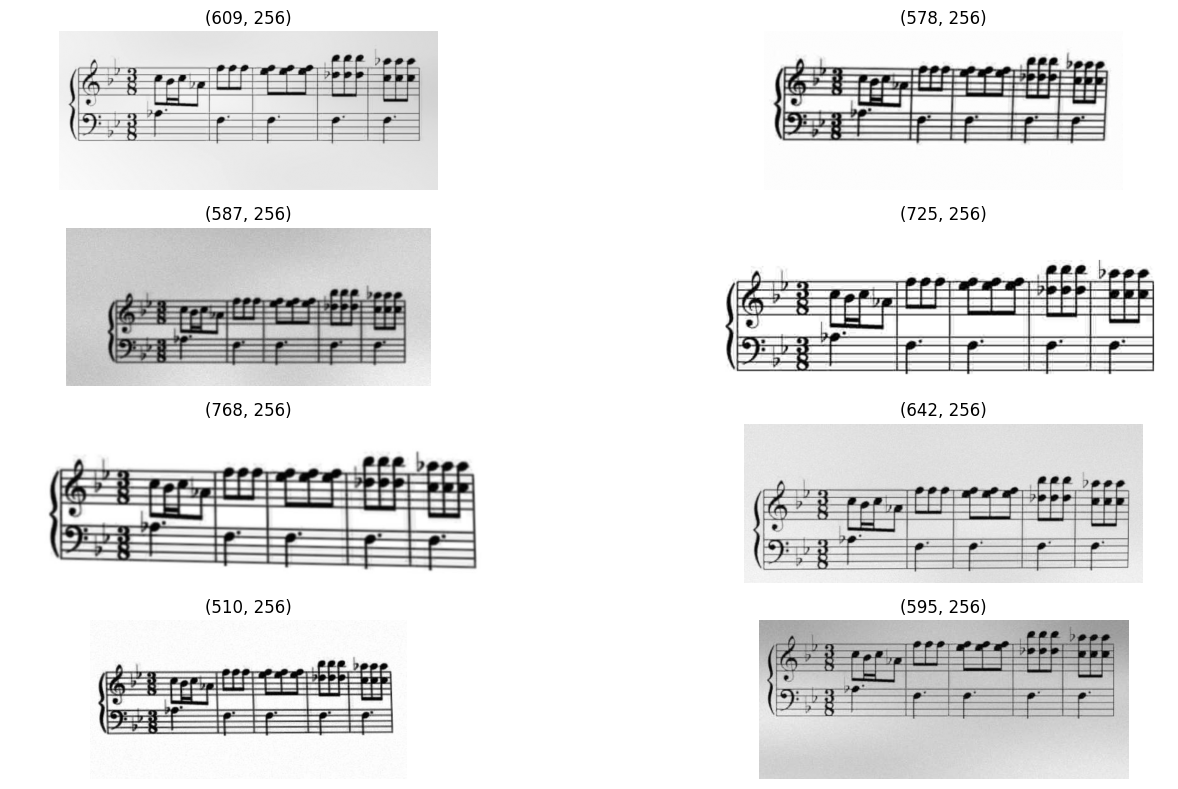

In [12]:
import matplotlib.pyplot as plt
aug = RandAug2()
raw = Image.open(io.BytesIO(train_ds.img_bytes[100])).convert("L")
fig, ax = plt.subplots(4, 2, figsize=(16, 8))
for a in ax.flat:
    im = aug(raw); a.imshow(im, cmap="gray"); a.set_title(f"{im.size}"); a.axis("off")
plt.tight_layout(); plt.show()

In [13]:
#Step 8 cell (augmented hook, mixed-condition selection, training loop)
CFG.update(tag="cnn_aug2", epochs=20, eval_every=2, lr_floor=0.05, grad_clip=1.0,
           workers=min(4, os.cpu_count()), resume=True)
cv2.setNumThreads(0)

# ---------- training-time augmentation: random strength per sample, ~25% clean ----------
class RandAug:
    def __init__(self, p_clean=0.25, p_group=0.7, smin=0.1, smax=1.0):
        self.p_clean, self.p_group, self.smin, self.smax = p_clean, p_group, smin, smax
    def __call__(self, img):
        if random.random() < self.p_clean:
            return img
        return Augment(random.uniform(self.smin, self.smax), p=self.p_group)(img)

train_ds.augment = RandAug2()
train_dl = DataLoader(Subset(train_ds, keep), collate_fn=collate, num_workers=CFG["workers"],
                      batch_sampler=WidthBucketSampler([train_ds.widths[i] for i in keep],
                                                       CFG["batch_size"]))

# ---------- fixed validation: same images, clean and degraded ----------
# val_deg = copy.copy(val_ds); val_deg.augment = Augment(0.75, deterministic=True)
val_deg = copy.copy(val_ds); val_deg.augment = Augment(0.75, deterministic=True)
val_lay = copy.copy(val_ds); val_lay.augment = DetLayoutDeg()
sel = val_idx[::6][:150]              # decoded for SER, clean + degraded = 300 decodes per check
loss_idx = val_idx[:500]              # val loss, clean + degraded

@torch.no_grad()
def val_loss(model, ds, idx):
    model.eval()
    dl = DataLoader(Subset(ds, idx), collate_fn=collate, num_workers=2,
                    batch_sampler=WidthBucketSampler([ds.widths[i] for i in idx], 16, shuffle=False))
    tot, n = 0.0, 0
    for b in dl:
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(b["image"].to(dev), b["widths"], b["tgt_in"].to(dev))
        tgt = b["tgt_out"].to(dev)
        tot += F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), tgt.reshape(-1),
                               ignore_index=PAD, reduction="sum").item()
        n += (tgt != PAD).sum().item()
    return tot / n

def quick_eval(model):
   out = []
   for ds in (val_ds, val_deg, val_lay):
       rows = score(ds, predict(model, ds, sel))
       out.append(100 * np.mean([e / n for _, n, e in rows]))
   return out                      # clean, degraded, layout + degraded                          # [clean mean SER, degraded mean SER]

# ---------- optimizer and schedule (same recipe as the baseline) ----------
def make_opt(model):
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (no_decay if p.ndim < 2 or "embed" in n else decay).append(p)
    return torch.optim.AdamW([{"params": decay, "weight_decay": 0.01},
                              {"params": no_decay, "weight_decay": 0.0}], lr=CFG["lr"])

total_steps = CFG["epochs"] * len(train_dl)
def lr_lambda(step):
    if step < CFG["warmup_steps"]:
        return (step + 1) / CFG["warmup_steps"]
    t = (step - CFG["warmup_steps"]) / max(1, total_steps - CFG["warmup_steps"])
    return CFG["lr_floor"] + (1 - CFG["lr_floor"]) * 0.5 * (1 + math.cos(math.pi * t))

seed_all(CFG["seed"])
model = OMRModel(len(itos), d=CFG["d_model"], layers=CFG["layers"],
                 heads=CFG["heads"], drop=CFG["dropout"]).to(dev)
opt = make_opt(model)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler("cuda")
last_p = f"{CFG['out_dir']}/{CFG['tag']}_last.pt"
best_p = f"{CFG['out_dir']}/{CFG['tag']}_best.pt"
start_ep, best, hist = 0, 1e9, []
if CFG["resume"] and os.path.exists(last_p):
    ck = torch.load(last_p, map_location=dev)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_ep, best, hist = ck["epoch"] + 1, ck["best"], ck["hist"]
    print("resumed from epoch", ck["epoch"])
print("params (M):", sum(p.numel() for p in model.parameters()) / 1e6, "| steps/epoch:", len(train_dl))

# ---------- train ----------
for ep in range(start_ep, CFG["epochs"]):
    model.train(); run, t0 = 0.0, time.time()
    for step, b in enumerate(train_dl):
        loss = batch_loss(model, b["image"], b["widths"], b)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item()
        if step % 400 == 0:
            print(f"ep {ep} step {step}/{len(train_dl)} loss {run/(step+1):.4f} "
                  f"lr {sched.get_last_lr()[0]:.2e} {(time.time()-t0)/(step+1):.2f}s/step")
    tr = run / len(train_dl)
    vc, vd, vl = (val_loss(model, d, loss_idx) for d in (val_ds, val_deg, val_lay))
    rec = dict(epoch=ep, train=tr, val_clean=vc, val_deg=vd, val_lay=vl)
    msg = f"EPOCH {ep} | train {tr:.4f} | val loss clean {vc:.4f} deg {vd:.4f} lay {vl:.4f}"
    if (ep + 1) % CFG["eval_every"] == 0 or ep == CFG["epochs"] - 1:
        sc, sd, sl = quick_eval(model); sel_score = (sc + sd + sl) / 3
        rec.update(ser_clean=sc, ser_deg=sd, ser_lay=sl, sel=sel_score)
        msg += f" | SER clean {sc:.2f} deg {sd:.2f} lay {sl:.2f} (select {sel_score:.2f})"
        if sel_score < best:
            best = sel_score
            torch.save({"model": model.state_dict(), "epoch": ep, "sel": sel_score}, best_p)
            msg += " *best*"
    hist.append(rec)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": ep, "best": best, "hist": hist}, last_p)
    json.dump(hist, open(f"{CFG['out_dir']}/{CFG['tag']}_history.json", "w"))
    print(msg, f"| {(time.time()-t0)/60:.1f} min")

params (M): 12.54054 | steps/epoch: 2543
ep 0 step 0/2543 loss 5.3262 lr 1.20e-06 1.59s/step
ep 0 step 400/2543 loss 2.4943 lr 2.41e-04 0.64s/step
ep 0 step 800/2543 loss 2.0351 lr 3.00e-04 0.56s/step
ep 0 step 1200/2543 loss 1.7490 lr 3.00e-04 0.52s/step
ep 0 step 1600/2543 loss 1.5572 lr 3.00e-04 0.49s/step
ep 0 step 2000/2543 loss 1.4164 lr 2.99e-04 0.46s/step
ep 0 step 2400/2543 loss 1.3034 lr 2.99e-04 0.44s/step
EPOCH 0 | train 1.2677 | val loss clean 0.5825 deg 0.5861 lay 0.5999 | 18.6 min
ep 1 step 0/2543 loss 0.7144 lr 2.99e-04 1.11s/step
ep 1 step 400/2543 loss 0.6027 lr 2.98e-04 0.33s/step
ep 1 step 800/2543 loss 0.5628 lr 2.98e-04 0.32s/step
ep 1 step 1200/2543 loss 0.5269 lr 2.97e-04 0.31s/step
ep 1 step 1600/2543 loss 0.4953 lr 2.96e-04 0.31s/step
ep 1 step 2000/2543 loss 0.4655 lr 2.95e-04 0.31s/step
ep 1 step 2400/2543 loss 0.4393 lr 2.95e-04 0.31s/step
decoded 150 samples in 17s
decoded 150 samples in 19s
decoded 150 samples in 19s
EPOCH 1 | train 0.4315 | val loss clea